## Experiment for the SoCG paper

This experiment has two goals: 
1. compute how many duplicates vs non duplicate switch points there are 
2. compute as a function of number of points how the number of switch points grows 

We start first with the number of points in each modules being balanced


In [5]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan     
import itertools
from scipy.stats import qmc
import math
import random as rnd

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
Omega_counts = {}
algo_names = ['2v2p', '2v2u','3v1']
poisson_intensity = 1
for i in range(1,3): 
    Omega_counts[(i,'d')] = [[],[],[]]
    Omega_counts[(i,'u')] = [[],[],[]]

**********
Computed 48 points (with duplicates)
Without duplicates 12
**********
Computed 126 points (with duplicates)
Without duplicates 30
**********
Computed 464 points (with duplicates)
Without duplicates 61
**********
Computed 53 points (with duplicates)
Without duplicates 9
**********
Computed 97 points (with duplicates)
Without duplicates 28
**********
Computed 528 points (with duplicates)
Without duplicates 56
**********
Computed 36 points (with duplicates)
Without duplicates 5
**********
Computed 116 points (with duplicates)
Without duplicates 23
**********
Computed 488 points (with duplicates)
Without duplicates 50
not enought points try again
**********
Computed 1717 points (with duplicates)
Without duplicates 361
**********
Computed 2182 points (with duplicates)
Without duplicates 624
**********
Computed 11410 points (with duplicates)
Without duplicates 1506
not enought points try again
**********
Computed 1625 points (with duplicates)
Without duplicates 374
**********
Comp

KeyError: (3, 'd')

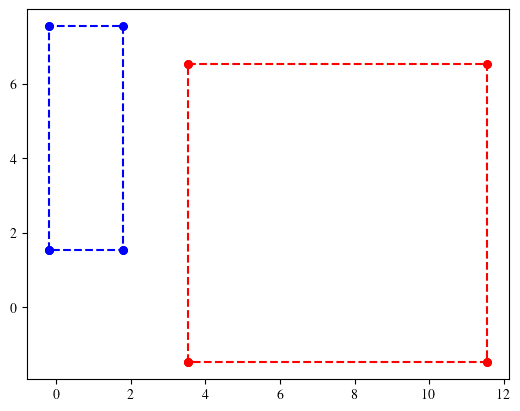

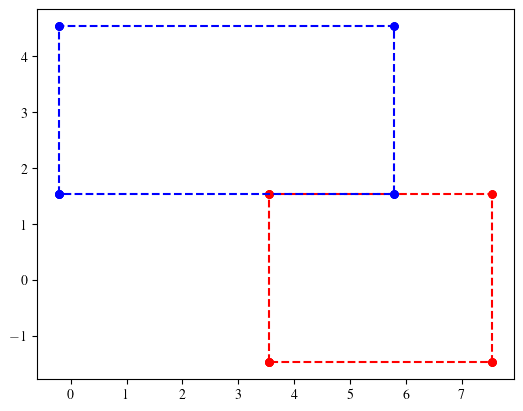

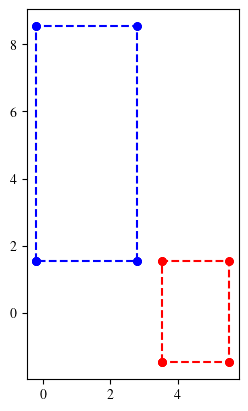

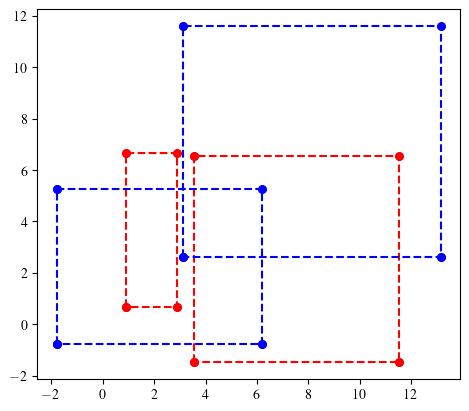

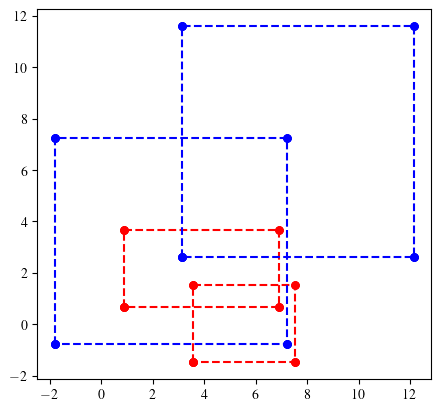

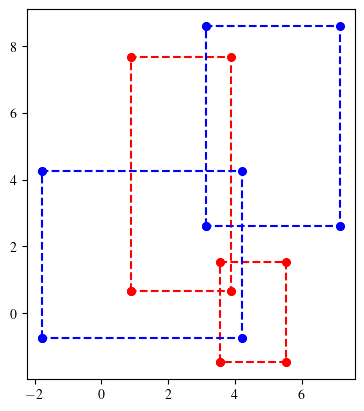

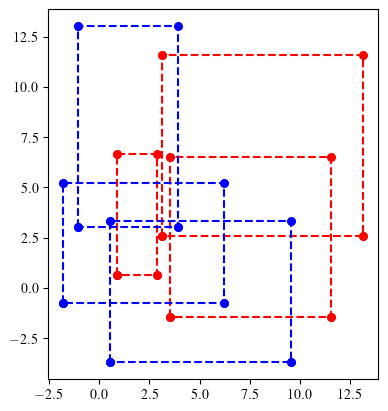

In [15]:
for exact_num in range(1,5):
    seeds = [0,1,2]
    for seed in seeds:
    
        CritPts = ex.make_rects_balanced(poisson_intensity, seed=seed, exact_num=exact_num)
        name = 'Counts/rects_balanced_' + str(exact_num)
    

        Pts2_2_paired, num_dup2_2_paired, num_pts2_2_paired, _ = omega.output_alg_2_2_paired(CritPts, name) 
        Pts2_2_unpaired, num_dup2_2_unpaired, num_pts2_2_unpaired, _ = omega.output_alg_2_2_unpaired(CritPts, name)
        Pts3_1, num_dup3_1, num_pts3_1 = omega.output_alg_3_1(CritPts, name)

        Omega_counts[(exact_num,'d')][0].append(num_dup2_2_paired)
        Omega_counts[(exact_num,'d')][1].append(num_dup2_2_unpaired)
        Omega_counts[(exact_num,'d')][2].append(num_dup3_1)

        Omega_counts[(exact_num,'u')][0].append(num_pts2_2_paired)
        Omega_counts[(exact_num,'u')][1].append(num_pts2_2_unpaired)
        Omega_counts[(exact_num,'u')][2].append(num_pts3_1)







## Plots 

In [ ]:
## plot 

average_dup = []
average_pts = []
sd_dup = []
sd_pts = [] 

